## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

RESULTS = Path('results_platoon_baseline')
TIDY    = RESULTS / 'tidy'

SCENARIO_ORDER = ['variable_packet_size', 'shadowing_blockage', 'high_density']
SCENARIO_COLORS = {
    'variable_packet_size': '#2c7bb6',
    'shadowing_blockage':   '#d7191c',
    'high_density':         '#fdae61',
}
SCENARIO_LABELS = {
    'variable_packet_size': 'VPS (control)',
    'shadowing_blockage':   'Shadowing',
    'high_density':         'High density',
}

def order_scenario(df):
    df = df.copy()
    df['scenario'] = pd.Categorical(df['scenario'], SCENARIO_ORDER, ordered=True)
    return df.sort_values('scenario')

rx   = order_scenario(pd.read_csv(TIDY / 'per_rx_kpis.csv'))
sinr = order_scenario(pd.read_csv(TIDY / 'sinr_per_rx.csv'))
ts   = order_scenario(pd.read_csv(TIDY / 'time_series.csv'))
ru   = order_scenario(pd.read_csv(TIDY / 'resource_usage.csv'))
hq   = order_scenario(pd.read_csv(TIDY / 'harq_stats.csv'))

scenarios = [s for s in SCENARIO_ORDER if s in rx.scenario.unique()]
print(f"per_rx_kpis  : {len(rx)} rows  scenarios={rx.scenario.unique().tolist()}")
print(f"               seeds/scenario={rx.groupby('scenario').seed.nunique().to_dict()}")
print(f"sinr_per_rx  : {len(sinr)} rows")
print(f"time_series  : {len(ts)} rows")
print(f"resource_use : {len(ru)} rows")
print(f"harq_stats   : {len(hq)} rows")

per_rx_kpis  : 810 rows  scenarios=['variable_packet_size', 'shadowing_blockage', 'high_density']
               seeds/scenario={'variable_packet_size': 30, 'shadowing_blockage': 30, 'high_density': 30}
sinr_per_rx  : 810 rows
time_series  : 49389 rows
resource_use : 647039 rows
harq_stats   : 90 rows


## 2. Headline: PRR by scenario

Each box shows the distribution of PRR across (RX node × seed) for one scenario.

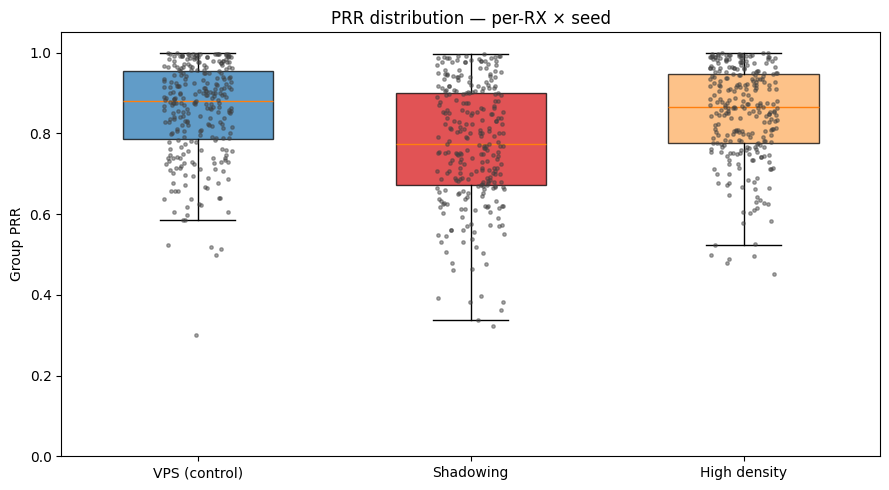

                       mean    std    min     p5
scenario                                        
variable_packet_size  0.855  0.118  0.299  0.637
shadowing_blockage    0.771  0.149  0.324  0.525
high_density          0.849  0.118  0.451  0.626


In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
data_lst  = [rx[rx.scenario == s]['prr'].dropna().to_numpy() for s in scenarios]
labels    = [SCENARIO_LABELS[s] for s in scenarios]
bp = ax.boxplot(data_lst, patch_artist=True, tick_labels=labels, widths=0.55, showfliers=False)
for box, s in zip(bp['boxes'], scenarios):
    box.set_facecolor(SCENARIO_COLORS[s]); box.set_alpha(0.75)
for i, s in enumerate(scenarios, 1):
    vals = rx[rx.scenario == s]['prr'].dropna().to_numpy()
    jitter = (np.random.rand(len(vals)) - 0.5) * 0.25
    ax.scatter(np.full_like(vals, i, dtype=float) + jitter, vals,
               s=6, color='0.25', alpha=0.45, zorder=3)
ax.set_ylabel('Group PRR'); ax.set_ylim(0, 1.05)
ax.set_title('PRR distribution — per-RX × seed')
fig.tight_layout(); plt.show()

# Summary stats
print(rx.groupby('scenario')['prr'].agg(['mean','std','min', lambda s: s.quantile(0.05)])
        .rename(columns={'<lambda_0>': 'p5'}).reindex(scenarios).round(3))

## 3. PRR, PIR, Throughput — all three metrics side-by-side

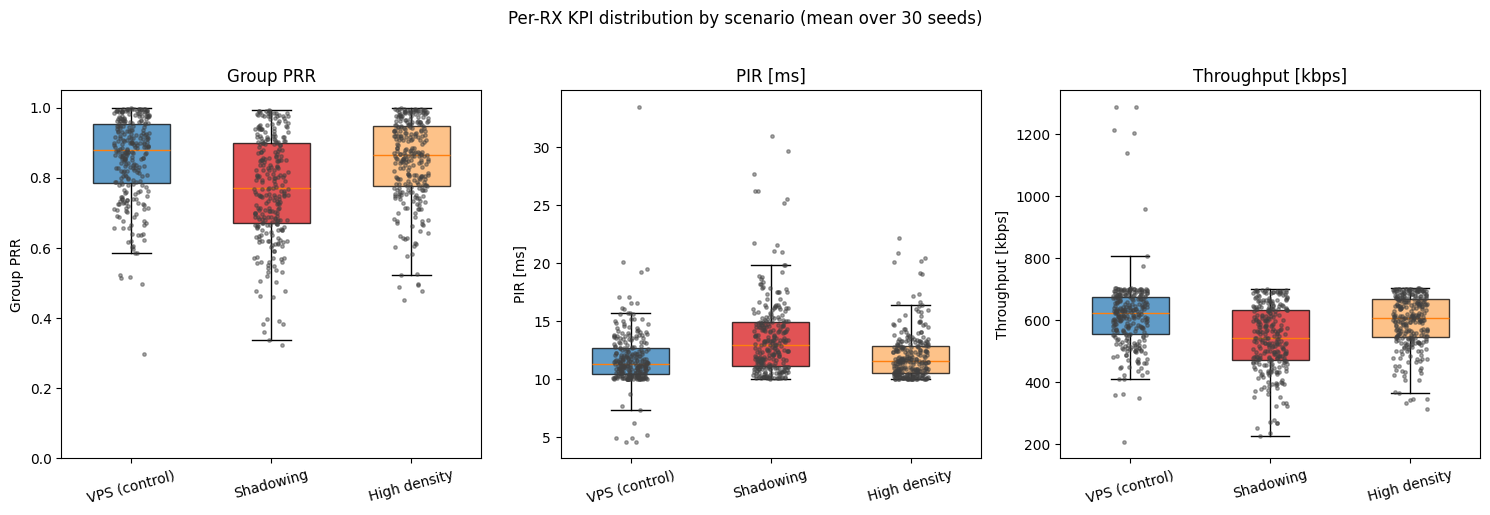

In [3]:
metrics = [
    ('prr',      'Group PRR',         (0, 1.05)),
    ('pir_ms',   'PIR [ms]',           None),
    ('tput_kbps','Throughput [kbps]',  None),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, label, ylim) in zip(axes, metrics):
    data_lst = [rx[rx.scenario == s][col].dropna().to_numpy() for s in scenarios]
    bp = ax.boxplot(data_lst, patch_artist=True,
                    tick_labels=[SCENARIO_LABELS[s] for s in scenarios],
                    widths=0.55, showfliers=False)
    for box, s in zip(bp['boxes'], scenarios):
        box.set_facecolor(SCENARIO_COLORS[s]); box.set_alpha(0.75)
    for i, s in enumerate(scenarios, 1):
        vals = rx[rx.scenario == s][col].dropna().to_numpy()
        jitter = (np.random.rand(len(vals)) - 0.5) * 0.25
        ax.scatter(np.full_like(vals, i, dtype=float) + jitter, vals,
                   s=6, color='0.25', alpha=0.45, zorder=3)
    ax.set_ylabel(label); ax.set_title(label)
    if ylim: ax.set_ylim(ylim)
    for t in ax.get_xticklabels(): t.set_rotation(15)
fig.suptitle('Per-RX KPI distribution by scenario (mean over 30 seeds)', y=1.02)
fig.tight_layout(); plt.show()

## 4. PRR vs TX-RX distance

Each point is one (RX node, seed) pair. Lines show mean ± std over seeds per RX node position.

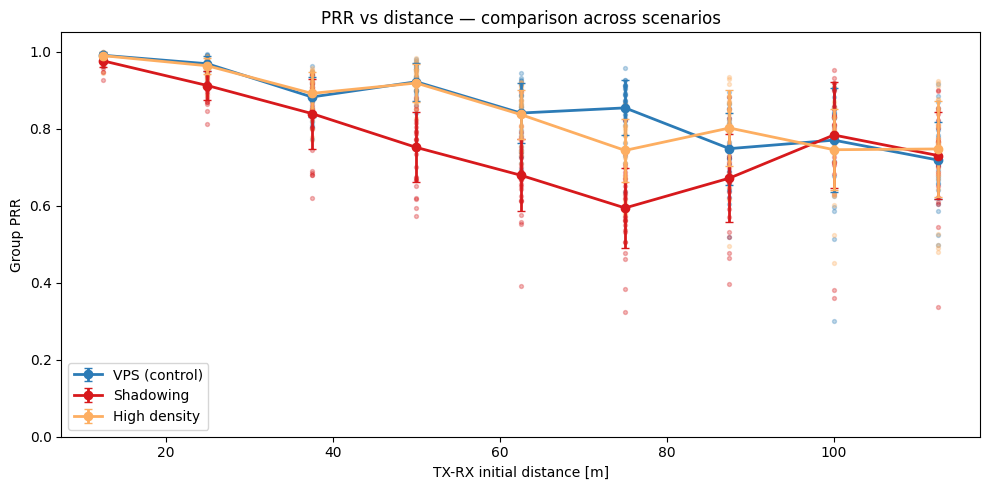

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for s in scenarios:
    sub = rx[rx.scenario == s]
    # Raw scatter
    ax.scatter(sub['init_dist_m'], sub['prr'], s=8,
               color=SCENARIO_COLORS[s], alpha=0.3)
    # Mean per RX node
    grp = sub.groupby('rx_node_id').agg(
        d=('init_dist_m', 'mean'),
        v=('prr', 'mean'),
        e=('prr', 'std')
    ).sort_values('d')
    ax.errorbar(grp.d, grp.v, yerr=grp.e, fmt='o-',
                color=SCENARIO_COLORS[s], capsize=3, lw=2,
                label=SCENARIO_LABELS[s])
ax.set_xlabel('TX-RX initial distance [m]')
ax.set_ylabel('Group PRR')
ax.set_ylim(0, 1.05)
ax.set_title('PRR vs distance — comparison across scenarios')
ax.legend()
fig.tight_layout(); plt.show()

## 5. SINR distribution per scenario

Per-RX mean SINR (dB) from `psschRxUePhy.avrgSinr`.

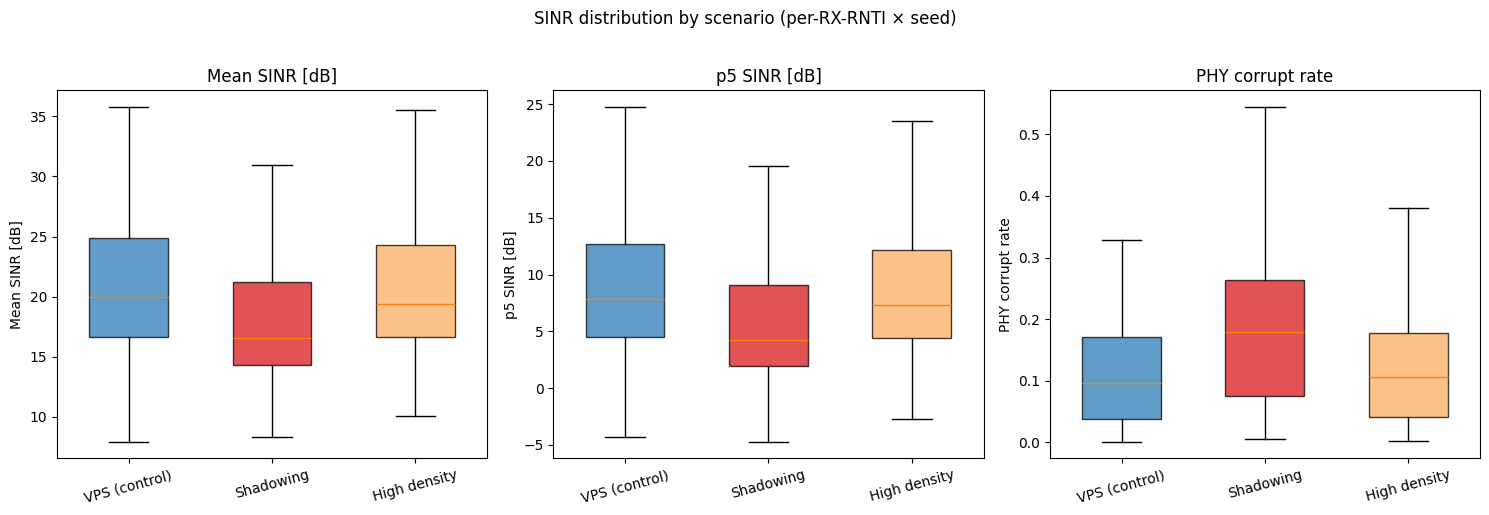

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sinr_metrics = [
    ('mean_sinr_db',   'Mean SINR [dB]'),
    ('p5_sinr_db',     'p5 SINR [dB]'),
    ('corrupt_rate',   'PHY corrupt rate'),
]
for ax, (col, label) in zip(axes, sinr_metrics):
    data_lst = [sinr[sinr.scenario == s][col].dropna().to_numpy() for s in scenarios]
    bp = ax.boxplot(data_lst, patch_artist=True,
                    tick_labels=[SCENARIO_LABELS[s] for s in scenarios],
                    widths=0.55, showfliers=False)
    for box, s in zip(bp['boxes'], scenarios):
        box.set_facecolor(SCENARIO_COLORS[s]); box.set_alpha(0.75)
    ax.set_ylabel(label); ax.set_title(label)
    for t in ax.get_xticklabels(): t.set_rotation(15)
fig.suptitle('SINR distribution by scenario (per-RX-RNTI × seed)', y=1.02)
fig.tight_layout(); plt.show()

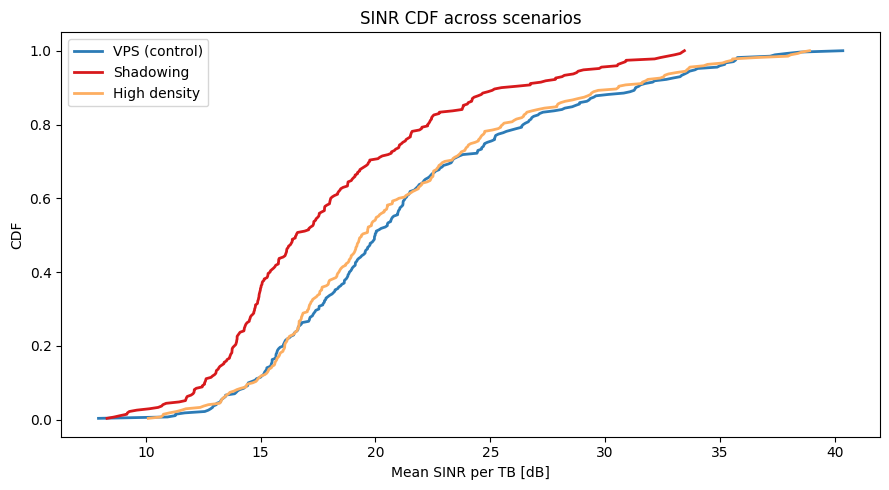

In [6]:
# SINR CDF comparison
fig, ax = plt.subplots(figsize=(9, 5))
for s in scenarios:
    vals = sinr[sinr.scenario == s]['mean_sinr_db'].dropna().sort_values().to_numpy()
    if len(vals) == 0: continue
    cdf = np.arange(1, len(vals)+1) / len(vals)
    ax.plot(vals, cdf, lw=2, color=SCENARIO_COLORS[s], label=SCENARIO_LABELS[s])
ax.set_xlabel('Mean SINR per TB [dB]')
ax.set_ylabel('CDF')
ax.set_title('SINR CDF across scenarios')
ax.legend()
fig.tight_layout(); plt.show()

## 6. SINR + PRR heat-map: RX node × scenario

Rows = RX node ID (1..9), columns = scenario. Cell = mean over seeds.

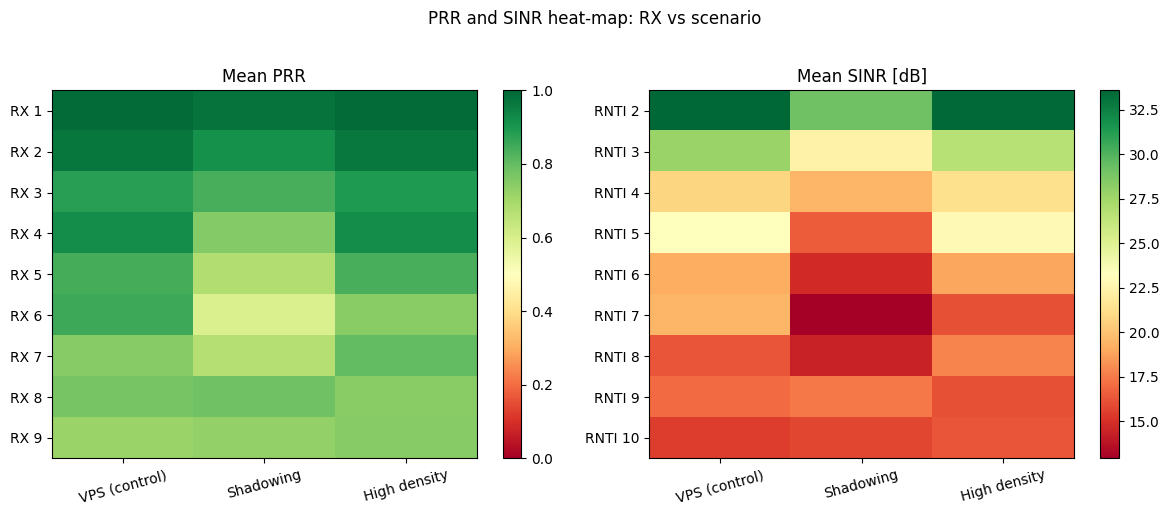

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# PRR heatmap
prr_piv = (rx[rx.rx_node_id != 0]
           .groupby(['rx_node_id', 'scenario'])['prr'].mean()
           .unstack('scenario')
           .reindex(columns=scenarios))
im0 = axes[0].imshow(prr_piv.values, aspect='auto', vmin=0, vmax=1,
                     cmap='RdYlGn', origin='upper')
axes[0].set_xticks(range(len(scenarios)))
axes[0].set_xticklabels([SCENARIO_LABELS[s] for s in scenarios], rotation=15)
axes[0].set_yticks(range(len(prr_piv)))
axes[0].set_yticklabels([f'RX {int(i)}' for i in prr_piv.index])
axes[0].set_title('Mean PRR')
plt.colorbar(im0, ax=axes[0])

# SINR heatmap — join sinr_per_rx on rx_rnti (RNTI = node index+1 in ns-3)
# We use rx_rnti as a proxy for rx_node_id here
sinr_piv = (sinr
            .groupby(['rx_rnti', 'scenario'])['mean_sinr_db'].mean()
            .unstack('scenario')
            .reindex(columns=scenarios))
im1 = axes[1].imshow(sinr_piv.values, aspect='auto',
                     cmap='RdYlGn', origin='upper')
axes[1].set_xticks(range(len(scenarios)))
axes[1].set_xticklabels([SCENARIO_LABELS[s] for s in scenarios], rotation=15)
axes[1].set_yticks(range(len(sinr_piv)))
axes[1].set_yticklabels([f'RNTI {int(i)}' for i in sinr_piv.index])
axes[1].set_title('Mean SINR [dB]')
plt.colorbar(im1, ax=axes[1])

fig.suptitle('PRR and SINR heat-map: RX vs scenario', y=1.02)
fig.tight_layout(); plt.show()

## 7. SINR time-series (per-scenario)

Mean SINR per 1-s bin from `psschRxUePhy`, averaged over seeds.

In [8]:
# Re-load psschRxUePhy data from all DBs for time-series SINR
# (extract_kpis.py aggregates per RX; for time-series we need to query DBs directly)
# NOTE: this cell requires the raw DB files. If slow, skip to §8.

import sqlite3, os

sinr_ts_rows = []
for db in sorted(RESULTS.rglob('*_seed*.db')):
    stem  = db.stem
    parts = stem.rsplit('_seed', 1)
    if len(parts) != 2: continue
    scen, seed = parts[0], int(parts[1])
    try:
        conn = sqlite3.connect(str(db))
        df = pd.read_sql_query(
            "SELECT timeMs/1000.0 as timeSec, rnti, avrgSinr FROM psschRxUePhy",
            conn)
        conn.close()
        df['scenario'] = scen
        df['seed']     = seed
        df['sinr_db']  = 10.0 * np.log10(df['avrgSinr'].clip(lower=1e-12))
        df['t_bin_s']  = (df['timeSec'] // 1.0).astype(float)
        sinr_ts_rows.append(df)
    except Exception as e:
        print(f'  [warn] {db.name}: {e}')

if sinr_ts_rows:
    sinr_ts = pd.concat(sinr_ts_rows, ignore_index=True)
    sinr_ts = order_scenario(sinr_ts)
    print(f'Loaded {len(sinr_ts)} SINR rows from {len(sinr_ts_rows)} DBs')
else:
    sinr_ts = pd.DataFrame()
    print('No SINR time-series data loaded')

Loaded 4952540 SINR rows from 90 DBs


/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_48497/2792455173.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap('viridis')


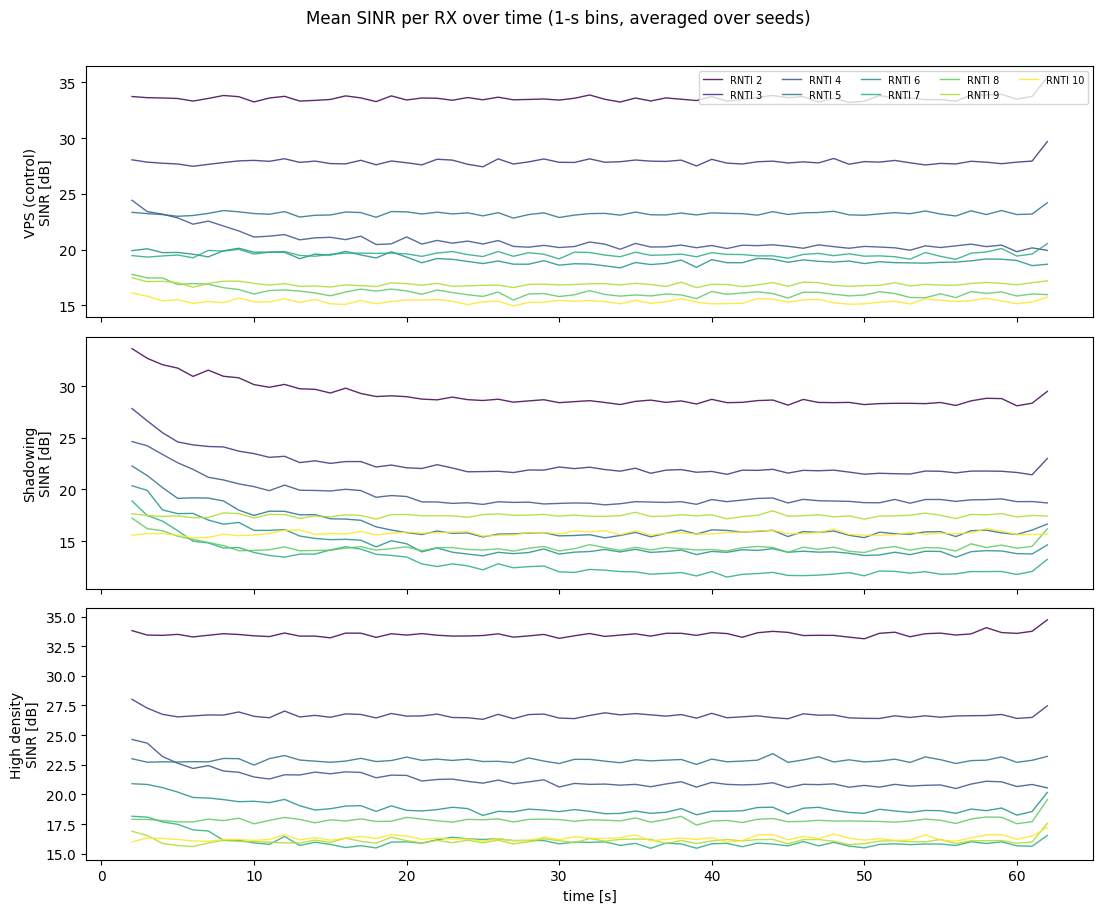

In [9]:
if not sinr_ts.empty:
    rntis  = sorted(sinr_ts['rnti'].unique())
    cmap   = cm.get_cmap('viridis')
    fig, axes = plt.subplots(len(scenarios), 1,
                              figsize=(11, 3.0*len(scenarios)),
                              sharex=True)
    axes = np.atleast_1d(axes)
    for ax, scen in zip(axes, scenarios):
        sub = sinr_ts[sinr_ts['scenario'] == scen]
        for j, rnti in enumerate(rntis):
            ss  = sub[sub['rnti'] == rnti]
            if ss.empty: continue
            agg = ss.groupby('t_bin_s')['sinr_db'].mean()
            ax.plot(agg.index, agg.values,
                    color=cmap(j / max(1, len(rntis)-1)),
                    lw=1.0, label=f'RNTI {rnti}', alpha=0.85)
        ax.set_ylabel(f'{SCENARIO_LABELS[scen]}\nSINR [dB]')
    axes[-1].set_xlabel('time [s]')
    axes[0].legend(fontsize=7, ncol=5, loc='upper right')
    fig.suptitle('Mean SINR per RX over time (1-s bins, averaged over seeds)', y=1.01)
    fig.tight_layout(); plt.show()
else:
    print('Skip: sinr_ts empty')

## 8. PRR time-series

Per-RX PRR in 1-s windows, averaged across seeds.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_48497/1301412560.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


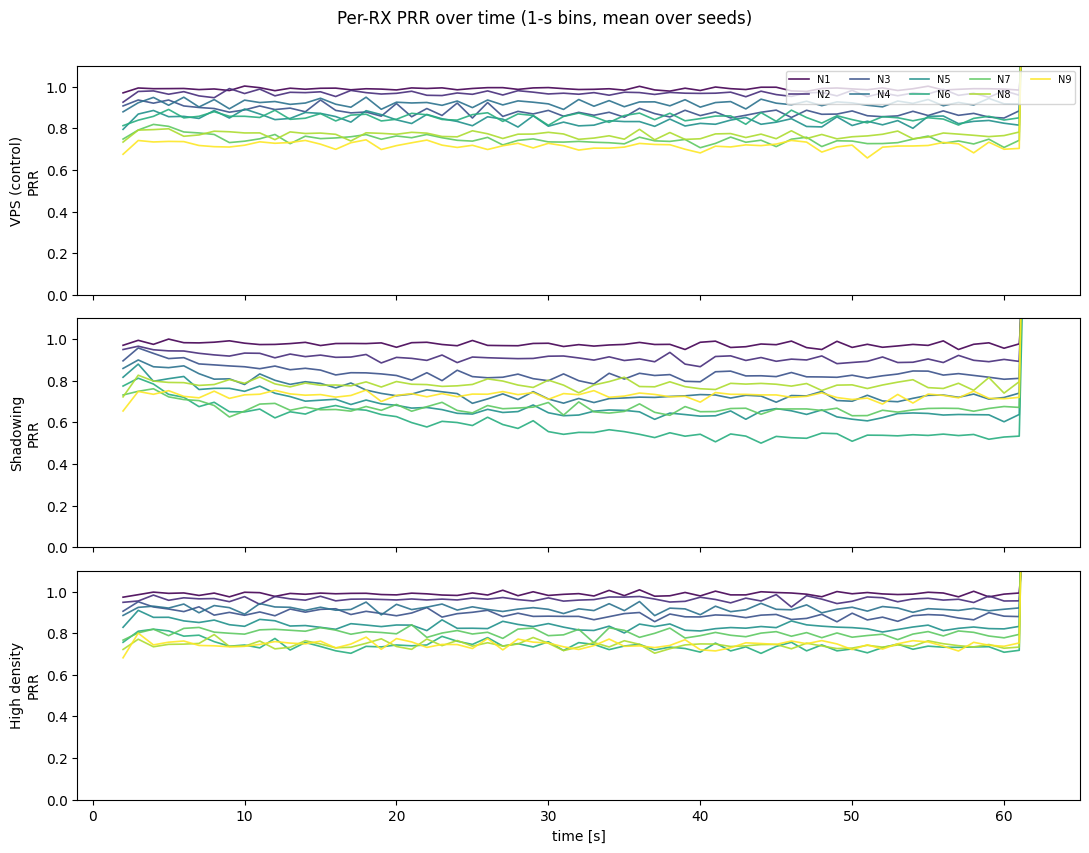

In [10]:
rx_nodes = sorted(ts['rx_node_id'].unique())
cmap = cm.get_cmap('viridis')
fig, axes = plt.subplots(len(scenarios), 1,
                          figsize=(11, 2.8*len(scenarios)),
                          sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, scen in zip(axes, scenarios):
    sub = ts[ts['scenario'] == scen]
    for j, nid in enumerate(rx_nodes):
        ss  = sub[sub['rx_node_id'] == nid]
        if ss.empty: continue
        agg = ss.groupby('t_bin_s')['prr_window'].mean()
        ax.plot(agg.index, agg.values,
                color=cmap(j/max(1, len(rx_nodes)-1)),
                lw=1.2, label=f'N{nid}', alpha=0.9)
    ax.set_ylabel(f'{SCENARIO_LABELS[scen]}\nPRR')
    ax.set_ylim(0, 1.1)
axes[-1].set_xlabel('time [s]')
axes[0].legend(fontsize=7, ncol=5, loc='upper right')
fig.suptitle('Per-RX PRR over time (1-s bins, mean over seeds)', y=1.01)
fig.tight_layout(); plt.show()

## 9. HARQ statistics by scenario

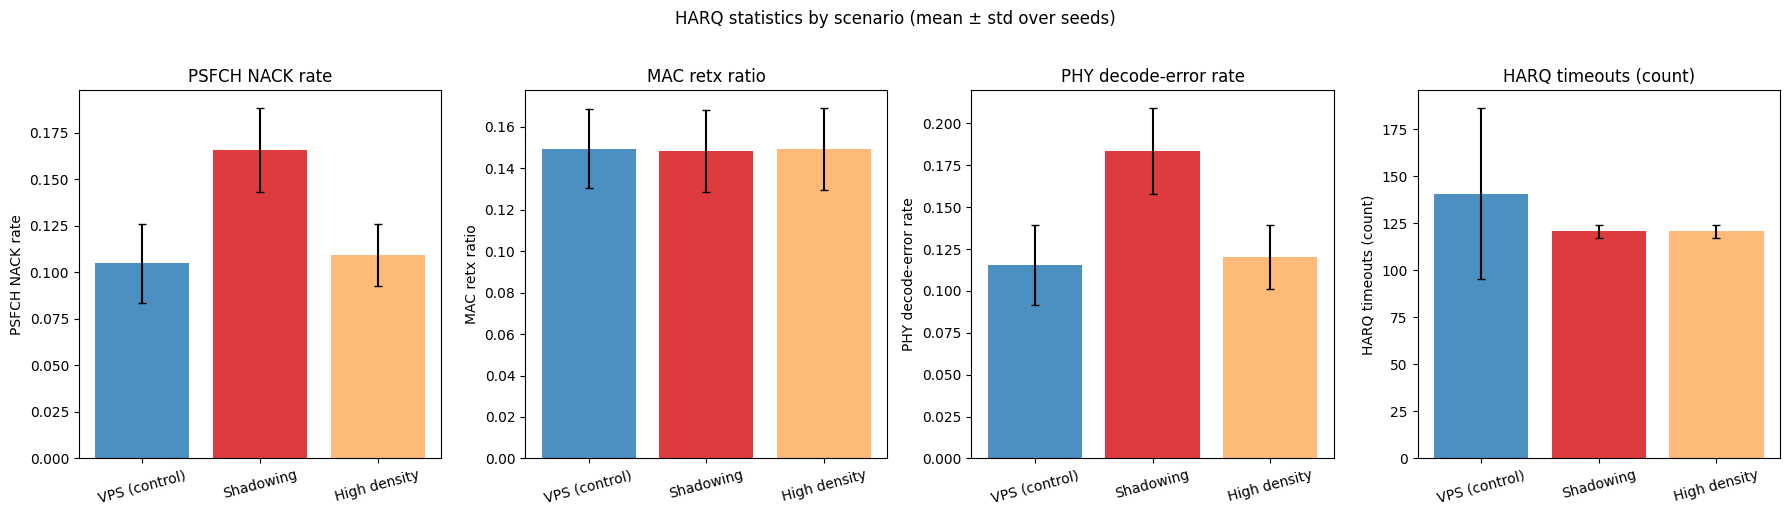

In [11]:
metrics = [
    ('nack_rate',     'PSFCH NACK rate'),
    ('retx_ratio',    'MAC retx ratio'),
    ('phy_err_rate',  'PHY decode-error rate'),
    ('timeout_count', 'HARQ timeouts (count)'),
]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (col, label) in zip(axes, metrics):
    agg = hq.groupby('scenario')[col].agg(['mean','std']).reindex(scenarios)
    ax.bar(range(len(scenarios)), agg['mean'], yerr=agg['std'],
           color=[SCENARIO_COLORS[s] for s in scenarios], alpha=0.85, capsize=3)
    ax.set_xticks(range(len(scenarios)))
    ax.set_xticklabels([SCENARIO_LABELS[s] for s in scenarios], rotation=15)
    ax.set_ylabel(label); ax.set_title(label)
fig.suptitle('HARQ statistics by scenario (mean ± std over seeds)', y=1.02)
fig.tight_layout(); plt.show()

## 10. Channel occupancy & resource usage

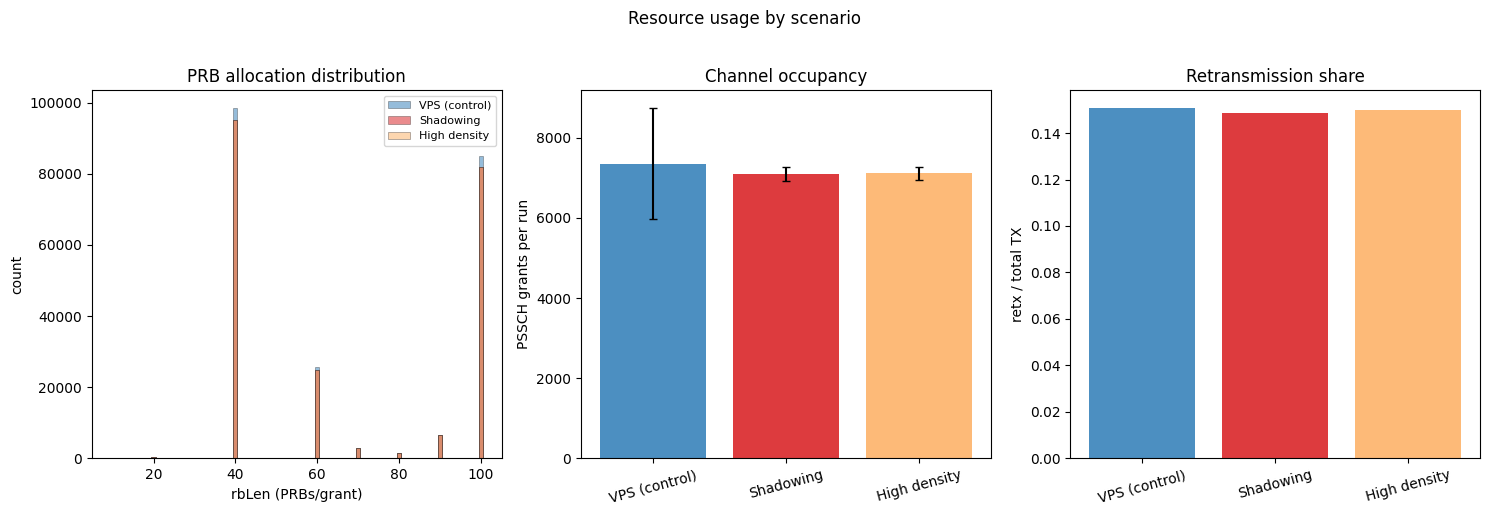

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# PRB allocation histogram
ax = axes[0]
for s in scenarios:
    vals = ru[ru['scenario'] == s]['rbLen'].to_numpy()
    if len(vals) == 0: continue
    bins = np.arange(vals.min(), vals.max()+2) - 0.5
    ax.hist(vals, bins=bins, alpha=0.5, label=SCENARIO_LABELS[s],
            color=SCENARIO_COLORS[s], edgecolor='black', lw=0.4)
ax.set_xlabel('rbLen (PRBs/grant)'); ax.set_ylabel('count')
ax.set_title('PRB allocation distribution'); ax.legend(fontsize=8)

# Grants per run
ax = axes[1]
grp = ru.groupby(['scenario','seed']).size().reset_index(name='n_grants')
means = grp.groupby('scenario')['n_grants'].agg(['mean','std']).reindex(scenarios)
ax.bar(range(len(scenarios)), means['mean'], yerr=means['std'],
       color=[SCENARIO_COLORS[s] for s in scenarios], alpha=0.85, capsize=3)
ax.set_xticks(range(len(scenarios)))
ax.set_xticklabels([SCENARIO_LABELS[s] for s in scenarios], rotation=15)
ax.set_ylabel('PSSCH grants per run'); ax.set_title('Channel occupancy')

# Retransmission share
ax = axes[2]
retx = []
for s in scenarios:
    sub = ru[ru['scenario'] == s]
    retx.append((sub['ndi'] == 0).sum() / max(1, len(sub)))
ax.bar(range(len(scenarios)), retx,
       color=[SCENARIO_COLORS[s] for s in scenarios], alpha=0.85)
ax.set_xticks(range(len(scenarios)))
ax.set_xticklabels([SCENARIO_LABELS[s] for s in scenarios], rotation=15)
ax.set_ylabel('retx / total TX'); ax.set_title('Retransmission share')

fig.suptitle('Resource usage by scenario', y=1.02)
fig.tight_layout(); plt.show()

## 11. Worst-RX analysis

The *worst RX* is the follower with the lowest mean PRR across seeds. This is the safety-critical perspective: the CACC controller is only as reliable as its worst link.

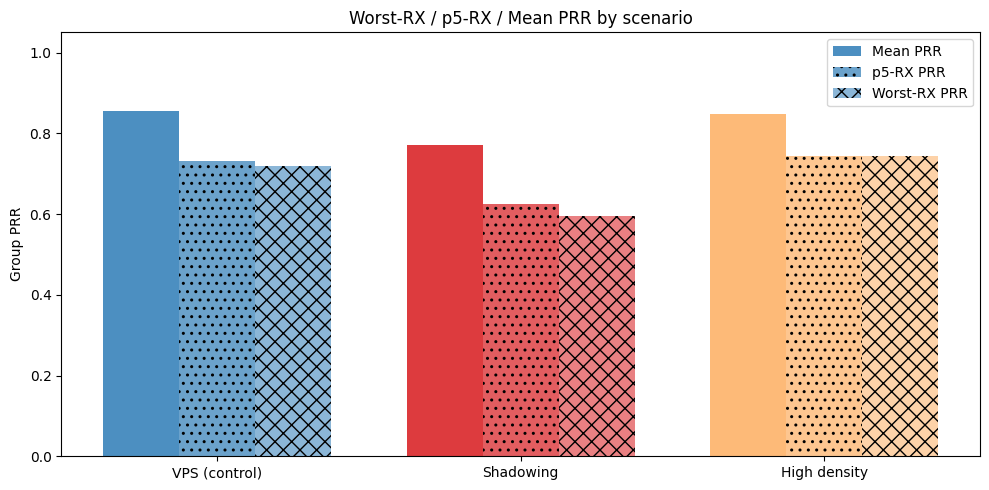


Worst-RX PRR:
scenario
variable_packet_size    0.718
shadowing_blockage      0.594
high_density            0.743

p5-RX PRR:
scenario
variable_packet_size    0.730
shadowing_blockage      0.625
high_density            0.744


In [13]:
# Worst-RX PRR: per scenario, min over rx_node_id of mean PRR over seeds
worst_rx = (rx[rx.rx_node_id != 0]
            .groupby(['scenario', 'rx_node_id'])['prr'].mean()
            .groupby('scenario').min()
            .reindex(scenarios))

# P5-RX: 5th percentile over rx_node_ids
p5_rx = (rx[rx.rx_node_id != 0]
         .groupby(['scenario', 'rx_node_id'])['prr'].mean()
         .groupby('scenario')
         .quantile(0.05)
         .reindex(scenarios))

# Mean PRR
mean_prr = rx[rx.rx_node_id != 0].groupby('scenario')['prr'].mean().reindex(scenarios)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(scenarios))
w = 0.25
ax.bar(x - w,   mean_prr.values,   width=w, label='Mean PRR',    alpha=0.85,
       color=[SCENARIO_COLORS[s] for s in scenarios])
ax.bar(x,       p5_rx.values,      width=w, label='p5-RX PRR',   alpha=0.7,
       color=[SCENARIO_COLORS[s] for s in scenarios], hatch='..')
ax.bar(x + w,   worst_rx.values,   width=w, label='Worst-RX PRR', alpha=0.55,
       color=[SCENARIO_COLORS[s] for s in scenarios], hatch='xx')
ax.set_xticks(x)
ax.set_xticklabels([SCENARIO_LABELS[s] for s in scenarios])
ax.set_ylabel('Group PRR'); ax.set_ylim(0, 1.05)
ax.set_title('Worst-RX / p5-RX / Mean PRR by scenario')
ax.legend()
fig.tight_layout(); plt.show()

print('\nWorst-RX PRR:')
print(worst_rx.round(3).to_string())
print('\np5-RX PRR:')
print(p5_rx.round(3).to_string())

## 12. Summary table

In [14]:
summary_rx = rx[rx.rx_node_id != 0].groupby('scenario').agg(
    prr_mean       = ('prr',      'mean'),
    prr_std        = ('prr',      'std'),
    prr_p5         = ('prr',      lambda s: s.quantile(0.05)),
    pir_mean_ms    = ('pir_ms',   'mean'),
    pir_p95_ms     = ('pir_ms',   lambda s: s.quantile(0.95)),
    tput_mean_kbps = ('tput_kbps','mean'),
    n_seeds        = ('seed',     'nunique'),
)
summary_harq = hq.groupby('scenario')[['nack_rate','retx_ratio','phy_err_rate']].mean()
summary_sinr = sinr.groupby('scenario')[['mean_sinr_db','p5_sinr_db','corrupt_rate']].mean()

summary = summary_rx.join(summary_harq).join(summary_sinr).reindex(scenarios)
summary['prr_worst_rx'] = worst_rx

print('Platoon Baseline Summary Table (mean over seeds × RX nodes)')
display(summary.style.format(precision=3)
        .background_gradient(subset=['prr_mean','prr_worst_rx','prr_p5'], cmap='RdYlGn', vmin=0, vmax=1)
        .background_gradient(subset=['mean_sinr_db','p5_sinr_db'], cmap='RdYlGn'))

Platoon Baseline Summary Table (mean over seeds × RX nodes)


,prr_mean,prr_std,prr_p5,pir_mean_ms,pir_p95_ms,tput_mean_kbps,n_seeds,nack_rate,retx_ratio,phy_err_rate,mean_sinr_db,p5_sinr_db,corrupt_rate,prr_worst_rx
scenario,,,,,,,,,,,,,,
variable_packet_size,0.855,0.118,0.637,11.769,15.463,617.014,30,0.105,0.150,0.115,21.408,9.196,0.115,0.718
shadowing_blockage,0.771,0.149,0.525,13.610,19.111,541.480,30,0.166,0.148,0.184,18.087,5.702,0.184,0.594
high_density,0.849,0.118,0.626,12.081,15.992,596.584,30,0.109,0.150,0.120,21.046,8.885,0.120,0.743


## Interpretation

- **`variable_packet_size`** is the cleanest baseline: open LOS for all followers, PRR should be high for nodes 1–6 and only drop slightly for nodes 7–9 (>100 m from leader at start).
- **`shadowing_blockage`**: the NLOSv truck (between followers 4 and 5, lane 1) widens the blocker AABB to `blockerW=6.4 m` so it reaches lane 0 (y=-8 m). Expect a step drop in SINR and PRR for followers 5–9 vs the VPS baseline.
- **`high_density`**: 75 background vehicles introduce additional NLOSv obstacles along the platoon. Depending on their lateral and longitudinal positions, expect broader SINR variance and potentially higher PHY corrupt rate than VPS.
- This 30-seed, fixed-MCS=14 dataset is the **baseline** for the adaptive-compression experiment (`traffic_class_compress_eval`): improved PRR in that campaign is meaningful only against these per-scenario bounds.